# 01 — Analisis Dataset Aksara Jawa

Dataset: 20 kelas aksara Jawa (ha, na, ca, ra, ka, da, ta, sa, wa, la, pa, dha, ja, ya, nya, ma, ga, ba, tha, nga).

Yang dianalisis:
1. Distribusi jumlah image per kelas (train/val)
2. Sample image tiap kelas
3. Dimensi & aspect ratio image
4. Statistik intensitas piksel

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

ROOT = Path('D:/Skripsi/AksaraJawa')
DATA = ROOT / 'Dataset'
TRAIN, VAL = DATA / 'train', DATA / 'val'
CLASSES = sorted([p.name for p in TRAIN.iterdir() if p.is_dir()])
print(f'Jumlah kelas: {len(CLASSES)}')
print('Kelas:', CLASSES)

Jumlah kelas: 20
Kelas: ['ba', 'ca', 'da', 'dha', 'ga', 'ha', 'ja', 'ka', 'la', 'ma', 'na', 'nga', 'nya', 'pa', 'ra', 'sa', 'ta', 'tha', 'wa', 'ya']


## 1. Distribusi Jumlah Image per Kelas

   kelas  train  val  total
0     ba    114   24    138
1     ca    108   24    132
2     da    108   24    132
3    dha    108   24    132
4     ga    108   24    132
5     ha    102   24    126
6     ja    108   24    132
7     ka    108   24    132
8     la    108   24    132
9     ma    108   24    132
10    na    108   24    132
11   nga    102   24    126
12   nya    108   24    132
13    pa    108   24    132
14    ra    108   24    132
15    sa    108   24    132
16    ta    108   24    132
17   tha    108   24    132
18    wa    108   24    132
19    ya    108   24    132

Total train: 2154 | val: 480 | grand total: 2634


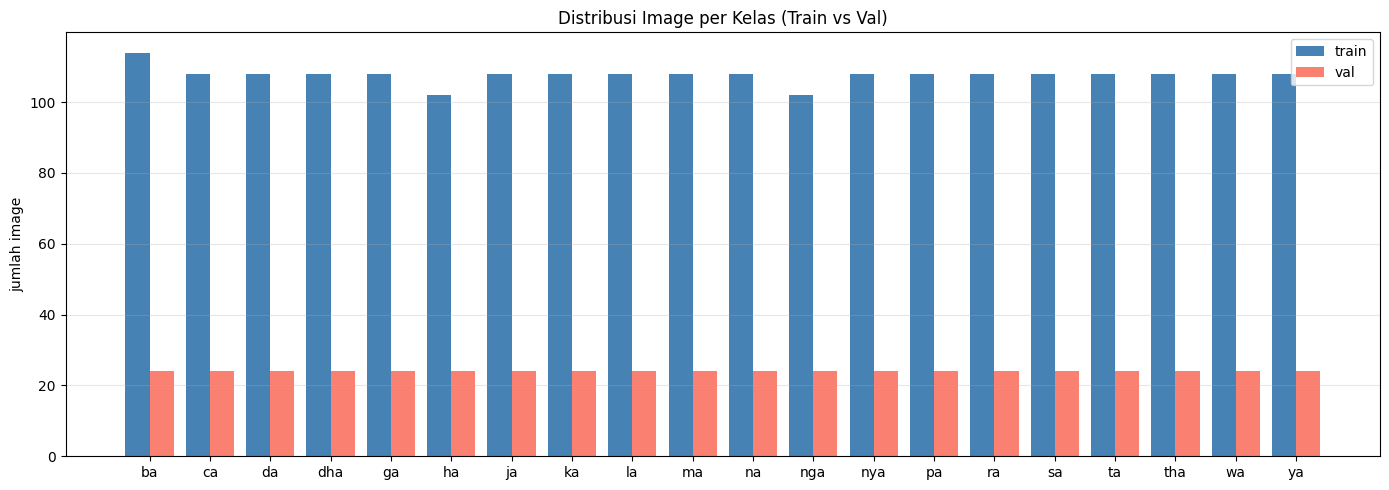

In [3]:
rows = []
for cls in CLASSES:
    n_train = len(list((TRAIN / cls).glob('*.png')))
    n_val = len(list((VAL / cls).glob('*.png')))
    rows.append({'kelas': cls, 'train': n_train, 'val': n_val, 'total': n_train + n_val})
df = pd.DataFrame(rows)
print(df)
print(f'\nTotal train: {df.train.sum()} | val: {df.val.sum()} | grand total: {df.total.sum()}')

fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(CLASSES))
ax.bar(x - 0.2, df.train, 0.4, label='train', color='steelblue')
ax.bar(x + 0.2, df.val, 0.4, label='val', color='salmon')
ax.set_xticks(x); ax.set_xticklabels(CLASSES, rotation=0)
ax.set_ylabel('jumlah image'); ax.set_title('Distribusi Image per Kelas (Train vs Val)')
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

## 2. Sample Image per Kelas

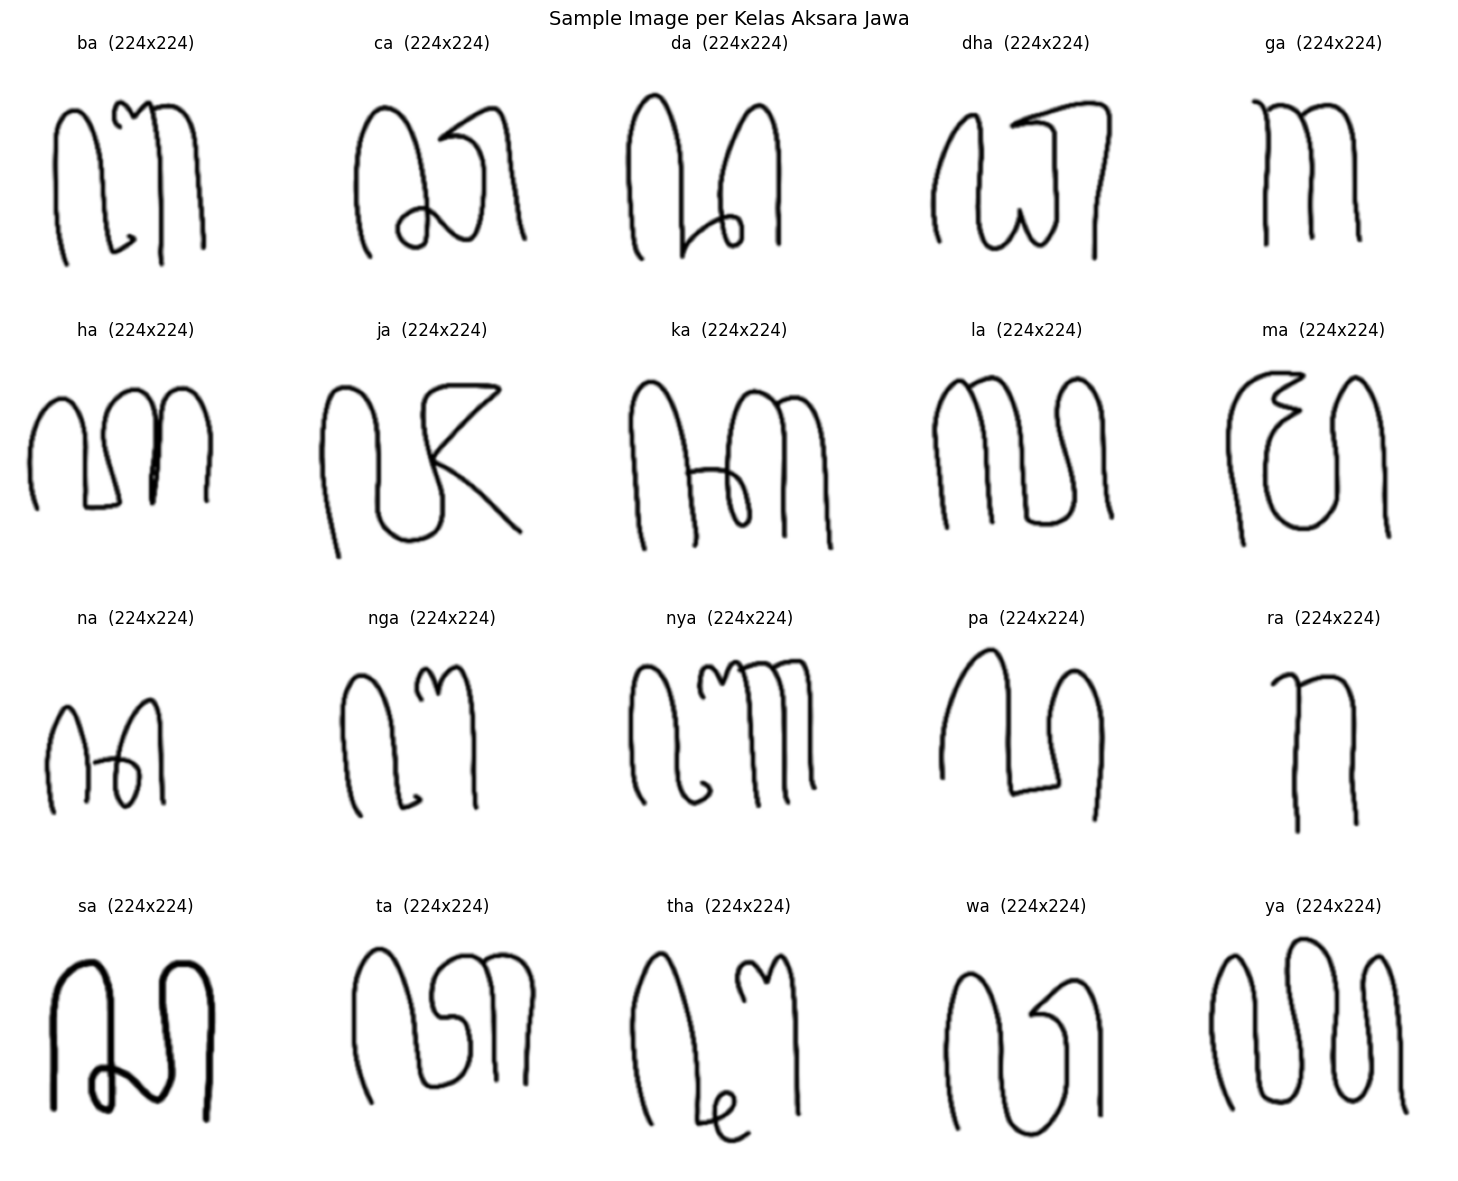

In [4]:
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
for ax, cls in zip(axes.flat, CLASSES):
    sample = next((TRAIN / cls).glob('*.png'))
    img = Image.open(sample)
    ax.imshow(img, cmap='gray' if img.mode == 'L' else None)
    ax.set_title(f'{cls}  ({img.size[0]}x{img.size[1]})')
    ax.axis('off')
plt.suptitle('Sample Image per Kelas Aksara Jawa', fontsize=14)
plt.tight_layout(); plt.show()

## 3. Dimensi & Aspect Ratio Image

            w       h   ratio
count  2154.0  2154.0  2154.0
mean    224.0   224.0     1.0
std       0.0     0.0     0.0
min     224.0   224.0     1.0
25%     224.0   224.0     1.0
50%     224.0   224.0     1.0
75%     224.0   224.0     1.0
max     224.0   224.0     1.0

Mode (channel) distribution:
mode
RGB    2154
Name: count, dtype: int64


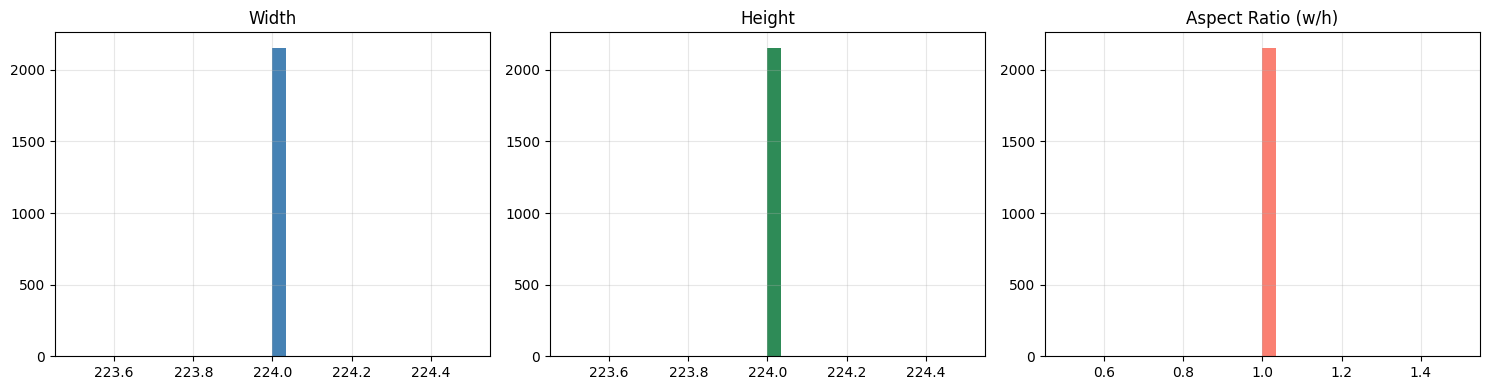

In [5]:
dims = []
for cls in CLASSES:
    for p in (TRAIN / cls).glob('*.png'):
        with Image.open(p) as im:
            dims.append({'kelas': cls, 'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
ddim = pd.DataFrame(dims)
ddim['ratio'] = ddim.w / ddim.h
print(ddim.describe())
print('\nMode (channel) distribution:')
print(ddim['mode'].value_counts())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(ddim.w, bins=30, color='steelblue'); axes[0].set_title('Width')
axes[1].hist(ddim.h, bins=30, color='seagreen'); axes[1].set_title('Height')
axes[2].hist(ddim.ratio, bins=30, color='salmon'); axes[2].set_title('Aspect Ratio (w/h)')
for a in axes: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. Statistik Intensitas Piksel

   kelas  mean_intensity  std_intensity
0     ba        0.944613       0.213920
1     ca        0.946926       0.206912
2     da        0.948182       0.207953
3    dha        0.947648       0.206099
4     ga        0.961774       0.180478
5     ha        0.949561       0.204402
6     ja        0.951916       0.198626
7     ka        0.939891       0.220578
8     la        0.942059       0.220347
9     ma        0.947005       0.205679
10    na        0.953521       0.195942
11   nga        0.954749       0.192810
12   nya        0.934093       0.230784
13    pa        0.954015       0.194386
14    ra        0.974303       0.147409
15    sa        0.949783       0.205208
16    ta        0.943494       0.214857
17   tha        0.948654       0.206038
18    wa        0.951601       0.198007
19    ya        0.939672       0.222147


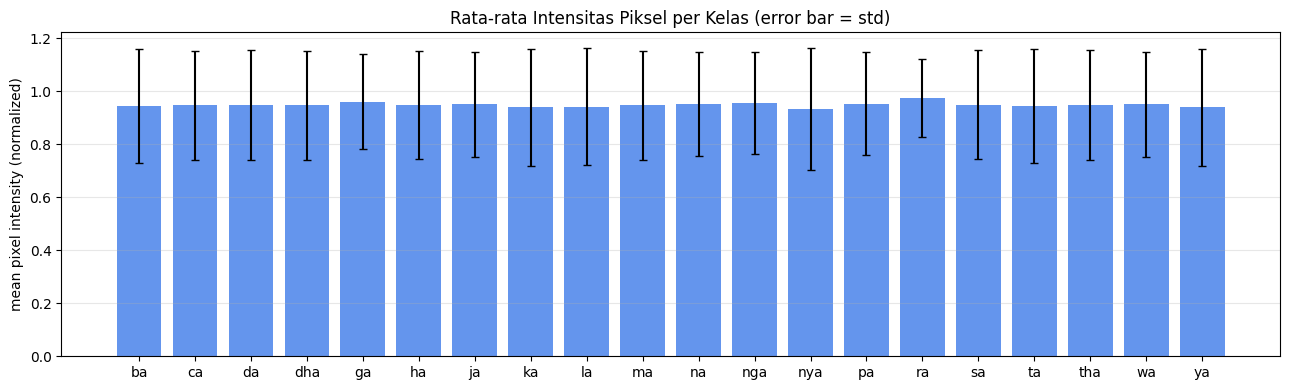

In [6]:
rng = np.random.default_rng(42)
stats = []
for cls in CLASSES:
    files = list((TRAIN / cls).glob('*.png'))
    sample = rng.choice(files, min(20, len(files)), replace=False)
    means, stds = [], []
    for p in sample:
        arr = np.asarray(Image.open(p).convert('RGB')) / 255.0
        means.append(arr.mean()); stds.append(arr.std())
    stats.append({'kelas': cls, 'mean_intensity': np.mean(means), 'std_intensity': np.mean(stds)})
dstat = pd.DataFrame(stats)
print(dstat)

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(dstat.kelas, dstat.mean_intensity, yerr=dstat.std_intensity, capsize=3, color='cornflowerblue')
ax.set_ylabel('mean pixel intensity (normalized)')
ax.set_title('Rata-rata Intensitas Piksel per Kelas (error bar = std)')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Variasi Augmentasi (filename pattern)

Dataset sudah ter-augmentasi — pattern filename: `.r10` (rotate +10°), `.rm10` (rotate -10°), `.b` (blur), `.meki`, dll.
Berikut breakdown jumlah variasi augmentasi yang ada.

      tag  count
0    mine    840
1   mine3    594
2       b    359
3     r10    359
4      r5    359
5    rm10    359
6     rm5    359
7   pred3    240
8   mine2    240
9    meki    120
10  nando    120


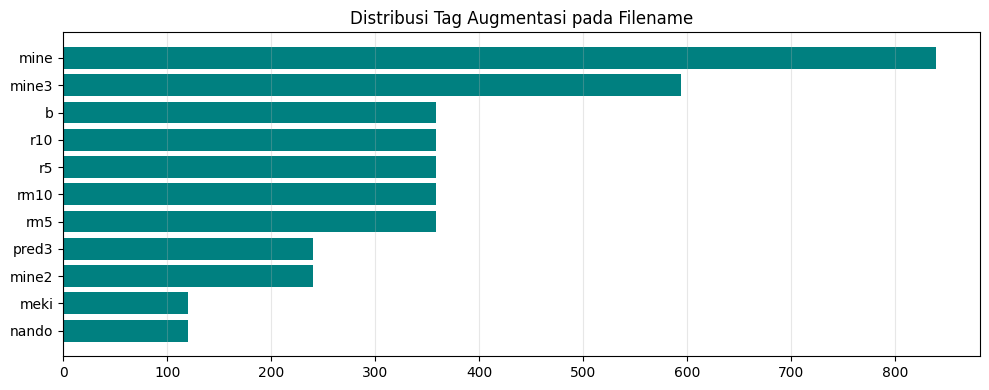

In [7]:
import re
from collections import Counter

tags = Counter()
for cls in CLASSES:
    for p in (TRAIN / cls).glob('*.png'):
        # extract tag(s): everything between first dot and .png
        stem = p.stem  # e.g. ha0.meki.r10
        parts = stem.split('.')[1:]  # skip identifier part
        if not parts:
            tags['(no_aug)'] += 1
        else:
            for t in parts: tags[t] += 1

tag_df = pd.DataFrame(tags.most_common(), columns=['tag', 'count'])
print(tag_df)

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(tag_df.tag, tag_df['count'], color='teal')
ax.set_title('Distribusi Tag Augmentasi pada Filename')
ax.invert_yaxis(); ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()